In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,mean_absolute_error,root_mean_squared_error,r2_score


In [2]:
df=pd.read_csv("house_price.csv")

In [5]:
df.shape

(47, 3)

In [6]:
df.describe()

,area,rooms,price
count,47.000000,47.000000,47.000000
mean,2000.680851,3.170213,340412.659574
std,794.702354,0.760982,125039.899586
min,852.000000,1.000000,169900.000000
25%,1432.000000,3.000000,249900.000000
50%,1888.000000,3.000000,299900.000000
75%,2269.000000,4.000000,384450.000000
max,4478.000000,5.000000,699900.000000


In [7]:
df.head()

,area,rooms,price
0,2104,3,399900
1,1600,3,329900
2,2400,3,369000
3,1416,2,232000
4,3000,4,539900


<Axes: xlabel='area', ylabel='price'>

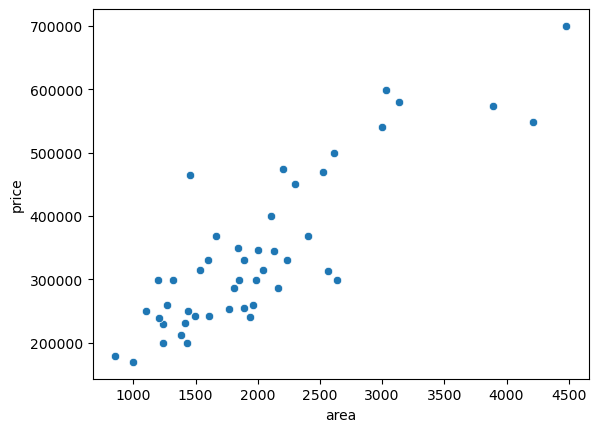

In [8]:
sns.scatterplot(x="area",y="price",data=df)

In [10]:
X = df.drop("price",axis=1)
y = df["price"]

In [11]:
X

,area,rooms
0,2104,3
1,1600,3
2,2400,3
3,1416,2
4,3000,4
5,1985,4
6,1534,3
7,1427,3
8,1380,3
9,1494,3


In [12]:
y

0     399900
1     329900
2     369000
3     232000
4     539900
5     299900
6     314900
7     198999
8     212000
9     242500
10    239999
11    347000
12    329999
13    699900
14    259900
15    449900
16    299900
17    199900
18    499998
19    599000
20    252900
21    255000
22    242900
23    259900
24    573900
25    249900
26    464500
27    469000
28    475000
29    299900
30    349900
31    169900
32    314900
33    579900
34    285900
35    249900
36    229900
37    345000
38    549000
39    287000
40    368500
41    329900
42    314000
43    299000
44    179900
45    299900
46    239500
Name: price, dtype: int64

In [16]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [17]:
model=LinearRegression()

In [18]:
model.fit(X_train,y_train)

LinearRegression()

In [19]:
model.intercept_

np.float64(84763.622522194)

In [20]:
model.coef_

array([   143.21853204, -13512.56442597])

In [21]:
model.predict

<bound method LinearModel.predict of LinearRegression()>

In [22]:
y_pred=model.predict(X_test)

In [23]:
y_pred

array([405995.94117864, 340351.83108993, 253038.54895937, 216088.16769291,
       601346.01888191, 221673.69044249, 314908.95480087, 464808.73543314,
       460368.96093988, 201766.31448886])

In [25]:
[y_pred,y_test]

[array([405995.94117864, 340351.83108993, 253038.54895937, 216088.16769291,
        601346.01888191, 221673.69044249, 314908.95480087, 464808.73543314,
        460368.96093988, 201766.31448886]),
 27    469000
 39    287000
 26    464500
 43    299000
 24    573900
 36    229900
 12    329999
 19    599000
 4     539900
 25    249900
 Name: price, dtype: int64]

In [26]:
r2_score(y_test,y_pred)

0.5148848812741442

In [27]:
mean_squared_error(y_test,y_pred)

8610424544.77767

In [28]:
mean_absolute_error(y_test,y_pred)

72334.75360356671

In [29]:
root_mean_squared_error(y_test,y_pred)

92792.37331148326

In [30]:
residuals = y_test - y_pred
residuals

27     63004.058821
39    -53351.831090
26    211461.451041
43     82911.832307
24    -27446.018882
36      8226.309558
12     15090.045199
19    134191.264567
4      79531.039060
25     48133.685511
Name: price, dtype: float64

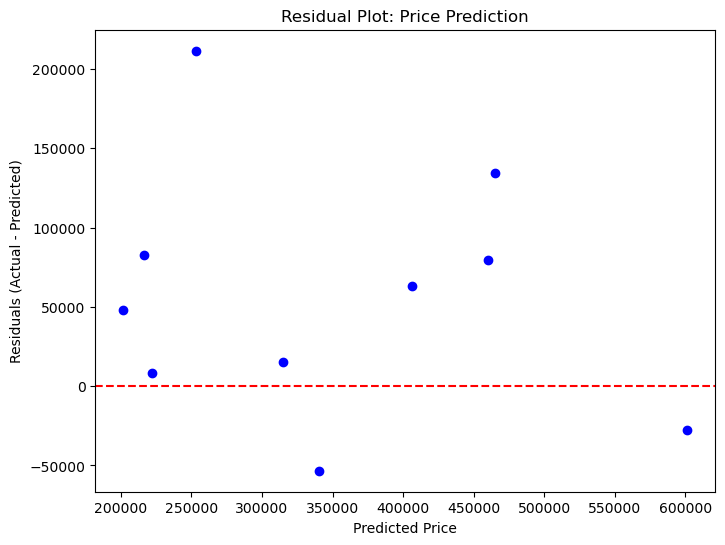

In [31]:
plt.figure(figsize=(8,6))
plt.scatter(y_pred, residuals, color="blue")
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Predicted Price")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot: Price Prediction")
plt.show()

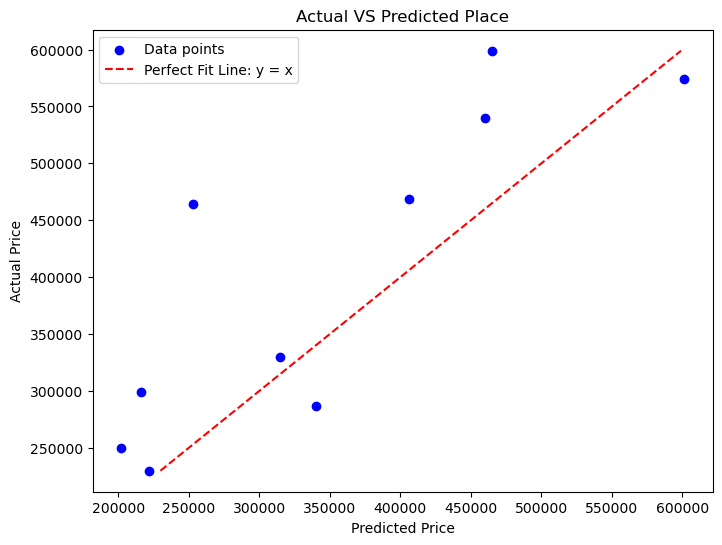

In [32]:
plt.figure(figsize=(8,6))
plt.scatter(y_pred, y_test, color="blue", label="Data points")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red", linestyle="--", label="Perfect Fit Line: y = x")
plt.xlabel("Predicted Price")
plt.ylabel("Actual Price")
plt.title("Actual VS Predicted Place")
plt.legend()
plt.show()